# Удовлетворённость авиапассажиров: модель и абляции

ДЗ 2 продолжает [исследование baseline](01_satisfaction_research.ipynb). Проверим, меняется ли качество при переходе от логистической регрессии к LightGBM и помогают ли два произведения оценок услуг. Данные — конкурсный `train.csv`, метрика — ROC-AUC. Результаты относятся к синтетическим конкурсным данным и не проверяют перенос на реальных пассажиров.

## Вопросы и протокол

1. Насколько отличается качество LightGBM от baseline на тех же признаках и разбиениях?
2. Меняют ли качество произведения оценок A = Wi-Fi × онлайн-посадка и B = комфорт кресла × развлечения?

E0 — логистическая регрессия из ДЗ 1; E1 — LightGBM на исходных признаках; E2 — LightGBM + A; E3 — LightGBM + B; E4 — LightGBM + A + B. Для каждого варианта используются одни и те же пять стратифицированных фолдов, seed 42 и одни и те же преобразования исходных признаков. Медиана, стандартизация, мода и one-hot обучаются только на обучающей части каждого фолда. Произведения считаются построчно без целевой переменной. Нули сохранены как числа: их смысл неизвестен.

Сравнение E1−E0 меняет семейство модели целиком. E4−E3 измеряет добавление A при наличии B, E4−E2 — добавление B при наличии A. E4−E1 показывает совместное изменение. Эти эффекты не обязаны складываться. Параметры и гипотезы описаны в [протоколе](../reports/hw2/protocol.md); ранние исследования этих данных могли повлиять на выбор вариантов.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image

root = Path.cwd()
if not (root / "configs/hw2.yaml").exists():
    root = root.parent
assert (root / "configs/hw2.yaml").exists(), "Запустите ноутбук из корня проекта или каталога notebooks"
report = root / "reports/hw2"
summary = pd.read_csv(report / "summary.csv")
folds = pd.read_csv(report / "folds.csv")
comparisons = pd.read_csv(report / "comparisons.csv")
slices = pd.read_csv(report / "slices.csv")

## Воспроизведение

Ниже показан сохранённый результат полного запуска. Чтобы заново обучить все 25 моделей, выполните из корня `./scripts/run_hw2.sh`, затем `python -m src.verify_hw2` и `python scripts/build_hw2_report.py`. После этого перезапустите ноутбук: он прочитает обновлённые таблицы. Инструкция по установке — в [README](../README.md). Результаты и параметры всех запусков доступны в таблицах `reports/hw2/`; подробный журнал и OOF-прогнозы создаются локально в `outputs/hw2/`.

## Качество моделей

Основной показатель — средний ROC-AUC пяти фолдов. В таблице дополнительно приведены стандартное отклонение по фолдам и средний average precision (AP). Объединённый OOF ROC-AUC считается отдельно и может отличаться от среднего из-за сравнений скоров между фолдами.

In [2]:
display(summary[["experiment", "model", "features", "mean_fold_auc", "std_fold_auc", "pooled_oof_auc", "mean_fold_ap", "fit_seconds_total"]].round(6))

,experiment,model,features,mean_fold_auc,std_fold_auc,pooled_oof_auc,mean_fold_ap,fit_seconds_total
0,E0,logistic,нет,0.921555,0.000436,0.921556,0.908974,12.015
1,E1,lightgbm,нет,0.958039,0.000668,0.958028,0.941970,82.376
2,E2,lightgbm,A,0.958028,0.000679,0.958015,0.941953,85.860
3,E3,lightgbm,B,0.958076,0.000626,0.958063,0.941925,87.942
4,E4,lightgbm,A+B,0.958059,0.000643,0.958049,0.941876,88.018


LightGBM на исходных признаках достигает среднего ROC-AUC **0,958039** против **0,921555** у логистической регрессии. Разница положительна на всех пяти фолдах; смена модели одновременно меняет несколько свойств, поэтому результат нельзя приписать отдельно нелинейности. В этой серии максимальное среднее у E3 — **0,958076**; это выбор по тем же данным, на которых оценивались варианты, а не независимое подтверждение преимущества.

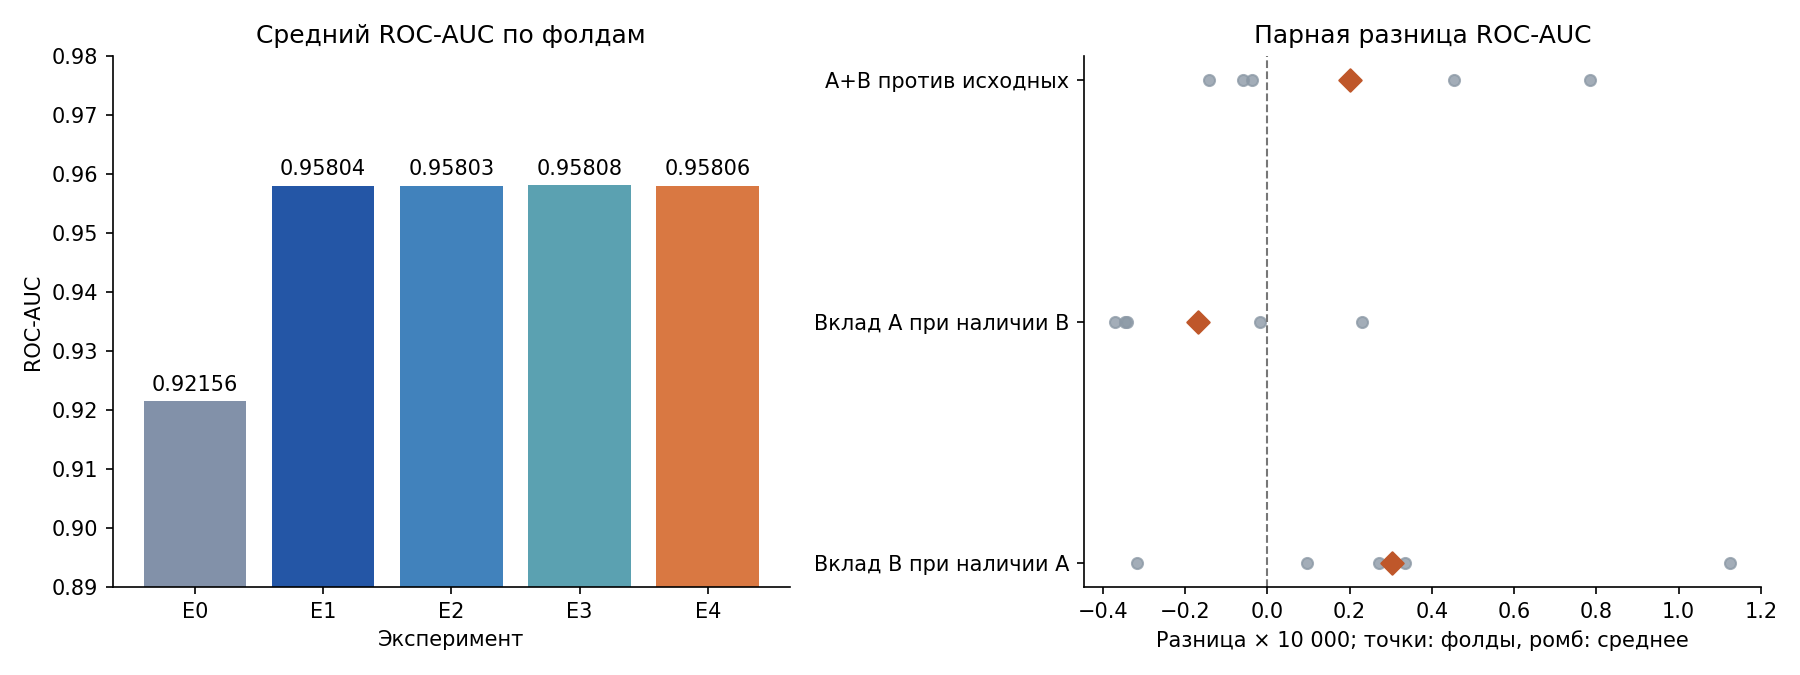

In [3]:
display(Image(filename=str(report / "comparison.png")))

На правом графике каждая точка — парная разница на одном фолде, ромб — среднее пяти разниц. Значения умножены на 10 000 для читаемости. Разброс между фолдами описательный: обучающие части пересекаются, поэтому точки нельзя считать пятью независимыми наборами данных.

## Абляции

В обоих сравнениях от полной конфигурации E4 убран ровно один признак. Положительная разница означает, что включение признака улучшило ROC-AUC на данном фолде.

In [4]:
columns = ["comparison", "left", "right", "mean_auc_delta", "std_auc_delta", "positive_folds"] + [f"fold_{i}_delta" for i in range(1, 6)]
display(comparisons[columns].round(7))

,comparison,left,right,mean_auc_delta,std_auc_delta,positive_folds,fold_1_delta,fold_2_delta,fold_3_delta,fold_4_delta,fold_5_delta
0,model,E1,E0,0.036483,0.000827,5,0.035593,0.035383,0.037357,0.036921,0.037162
1,both_features,E4,E1,0.000020,0.000036,2,-0.000004,0.000078,-0.000006,-0.000014,0.000045
2,ablate_A,E4,E3,-0.000017,0.000024,1,-0.000037,-0.000035,0.000023,-0.000034,-0.000002
3,ablate_B,E4,E2,0.000030,0.000047,4,0.000034,0.000113,0.000027,-0.000032,0.000010


Совместное добавление A и B к E1 даёт в среднем **+0,000020**, но разница положительна только в двух фолдах из пяти. Добавление A к модели с B даёт **−0,000017** в среднем и положительную разницу в одном фолде; добавление B к модели с A — **+0,000030**, положительную в четырёх. Эффекты малы по сравнению с заменой модели, а знак меняется между фолдами. Эти данные не позволяют уверенно утверждать, что взаимодействия устойчиво улучшают качество. Отрицательные результаты сохранены наряду с положительными.

## Срез по типу поездки

Сравним объединённый OOF ROC-AUC исходной логистической модели и двух LightGBM. В каждом срезе доля положительного класса различается. Срез описательный; он не доказывает причину ошибок и не является отдельной проверочной выборкой.

In [5]:
display(slices.round(6))

,experiment,type_of_travel,n,positive_rate,pooled_oof_auc
0,E0,Business travel,497441,0.584337,0.919792
1,E0,Personal Travel,202194,0.097263,0.651831
2,E1,Business travel,497441,0.584337,0.953475
3,E1,Personal Travel,202194,0.097263,0.826383
4,E4,Business travel,497441,0.584337,0.953456
5,E4,Personal Travel,202194,0.097263,0.826458


На личных поездках ROC-AUC вырастает с **0,651831** у E0 до **0,826383** у E1, но остаётся ниже, чем на деловых поездках (**0,953475** у E1). У E4 этот разрыв тоже сохраняется. Эти значения не показывают качество при конкретном пороге или полезность для авиакомпании; калибровка и перенос не проверялись.

## Ограничения и выводы

На выбранных фолдах переход к LightGBM улучшил ранжирование относительно baseline. Два заданных взаимодействия дали малые и неоднородные изменения; на основании этой серии их практическая польза не установлена. Предыдущая работа с конкурсом использовала те же данные, поэтому исследование не является независимым подтверждением. Доверительный интервал из ДЗ 1 относится только к объединённому OOF ROC-AUC baseline при фиксированных прогнозах; он не является интервалом разницы моделей и не учитывает переобучение моделей.

Для продолжения можно повторить фиксированные сравнения на других разбиениях и проверить срезы, не считая эти разбиения независимыми датасетами; отдельный интерес представляет исключение оценок услуг, если нужен сценарий без них. Реальный перенос требует новых данных и уточнения времени доступности признаков.